<a href="https://colab.research.google.com/github/Storm00212/Signals-and-communication-visualisation/blob/main/SIGNALS_Q3_SIGNALS_PRACTICE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

#

In [14]:
t= np.linspace(-5, 5, 1000)
n = np.array([1, 2, 3, 4, 5, 50])
g= np.cos(2*np.pi*t*n[4])
h= np.heaviside(t+1, 1)- np.heaviside(t-1, 1)
x= g*h
N=len(t)


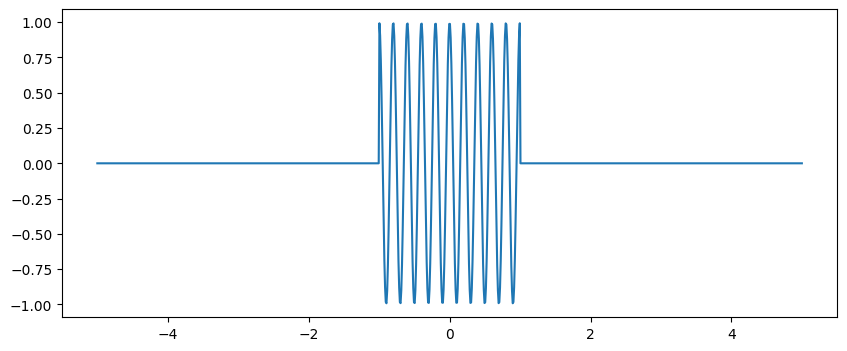

In [15]:
plt.figure(figsize=(10, 4))
plt.plot(t, x)
plt.show()

/usr/local/lib/python3.12/dist-packages/matplotlib/cbook.py:1709: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/usr/local/lib/python3.12/dist-packages/matplotlib/cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


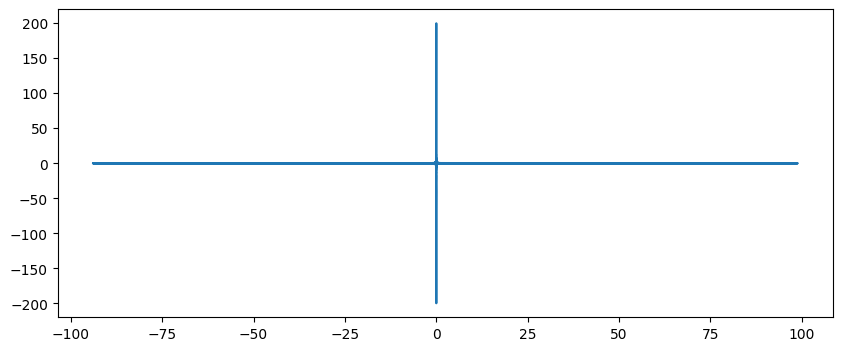

In [16]:
fourier = np.fft.fft(x)
f= 1/t

plt.figure(figsize=(10, 4))
plt.plot(fourier, f)
plt.show()

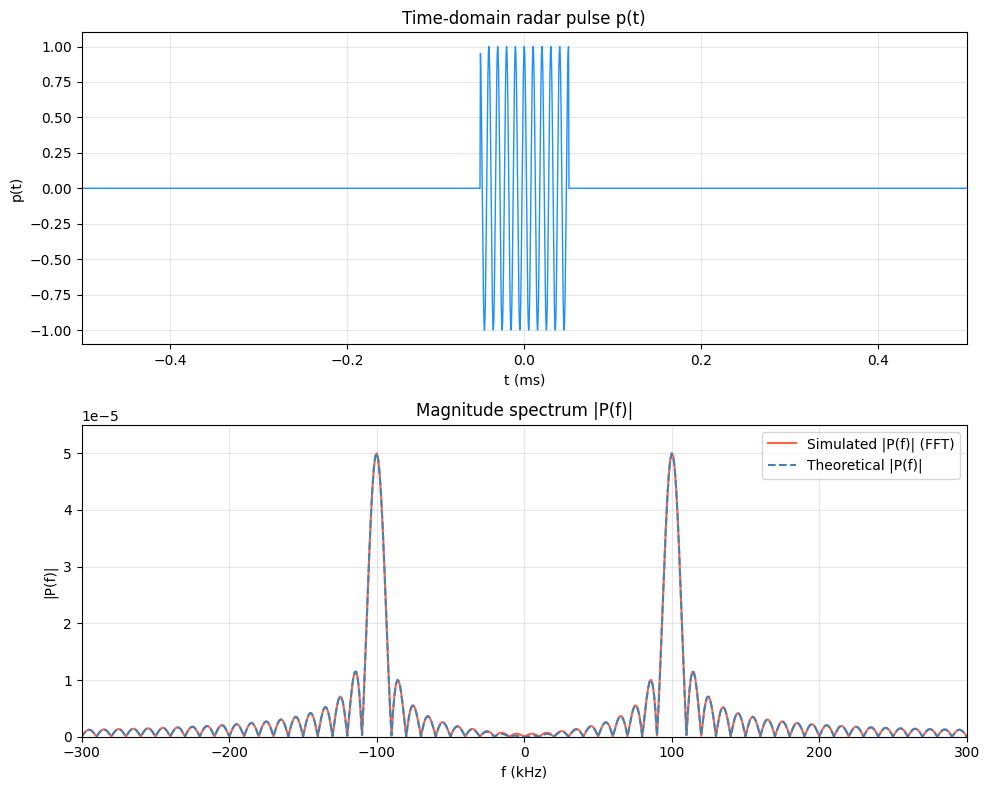

In [17]:
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Simulation Parameters ---
fs = 2000e3          # Sampling frequency: 2 MHz (to smoothly capture up to 300 kHz)
dt = 1 / fs          # Time step
t_total = 1.0e-3     # Total time duration: 1.0 ms (-0.5 ms to 0.5 ms)
t = np.arange(-t_total/2, t_total/2, dt)

# --- 2. Define the Radar Pulse ---
fc = 100e3           # Carrier frequency: 100 kHz
T_pulse = 0.1e-3     # Pulse width: 0.1 ms (-0.05 ms to 0.05 ms)

# Create a rectangular window that is 1 between -0.05ms and 0.05ms, and 0 elsewhere
rect_window = np.where(np.abs(t) <= T_pulse / 2, 1.0, 0.0)
p_t = np.cos(2 * np.pi * fc * t) * rect_window

# --- 3. Compute the Fourier Transform (FFT) ---
N = len(t)
# Compute raw FFT
P_raw = np.fft.fft(p_t)
# Shift zero-frequency component to the center of the spectrum
P_shifted = np.fft.fftshift(P_raw)
# Get centered frequency array
frequencies = np.fft.fftshift(np.fft.fftfreq(N, d=dt))

# Scale magnitude to match Continuous Fourier Transform amplitude (multiply by dt)
simulated_magnitude = np.abs(P_shifted) * dt

# --- 4. Compute Theoretical Magnitude Spectrum ---
# P(f) = T/2 * [sinc(T*(f-fc)) + sinc(T*(f+fc))]
# Note: np.sinc(x) in NumPy computes sin(pi*x)/(pi*x)
theoretical_magnitude = (T_pulse / 2) * (
    np.sinc(T_pulse * (frequencies - fc)) +
    np.sinc(T_pulse * (frequencies + fc))
)
theoretical_magnitude = np.abs(theoretical_magnitude)

# --- 5. Plotting ---
plt.figure(figsize=(10, 8))

# Top Plot: Time Domain
plt.subplot(2, 1, 1)
plt.plot(t * 1e3, p_t, color='dodgerblue', linewidth=1)  # Convert time to ms
plt.title('Time-domain radar pulse p(t)')
plt.xlabel('t (ms)')
plt.ylabel('p(t)')
plt.xlim(-0.5, 0.5)
plt.ylim(-1.1, 1.1)
plt.grid(True, alpha=0.3)

# Bottom Plot: Frequency Domain
plt.subplot(2, 1, 2)
plt.plot(frequencies / 1e3, simulated_magnitude, color='tomato', label='Simulated |P(f)| (FFT)', linewidth=1.5) # Convert freq to kHz
plt.plot(frequencies / 1e3, theoretical_magnitude, color='steelblue', linestyle='--', label='Theoretical |P(f)|', linewidth=1.5)
plt.title('Magnitude spectrum |P(f)|')
plt.xlabel('f (kHz)')
plt.ylabel('|P(f)|')
plt.xlim(-300, 300)
plt.ylim(0, 5.5e-5)
plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
